# Fixed-OP DTOF variation across subjects

This notebook visualizes the DTOF curves of all 154 subjects at one fixed optical-property (OP) condition and SDS1. The plotted signal is the raw simulated DTOF with only a base-10 logarithm applied; no area normalization, z-score normalization, or amplitude rescaling is used.

Because $\log_{10}(0)$ is undefined, samples whose raw value is zero are displayed as gaps rather than being replaced by an arbitrary constant.

In [25]:
from pathlib import Path
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from the project root or notebooks directory.')

os.chdir(ROOT)

def first_existing_path(*relative_paths):
    for relative_path in relative_paths:
        candidate = ROOT / relative_path
        if candidate.is_file():
            return candidate
    searched = ', '.join(str(ROOT / path) for path in relative_paths)
    raise FileNotFoundError(f'None of the expected files exists: {searched}')

DTOF_PATH = first_existing_path(
    'data/raw/stage1/dataset_dtof.mat',
    'data/dataset_dtof.mat',
)
OP_PATH = first_existing_path(
    'data/raw/stage1/dataset_OP.mat',
    'data/dataset_OP.mat',
)
FIGURE_DIR = ROOT / 'results' / 'figures' / 'stage1'
FIGURE_PATH = FIGURE_DIR / 'dtof_subject_variation_fixed_op_sds1.png'

print(f'Project root: {ROOT}')
print(f'DTOF data:   {DTOF_PATH.relative_to(ROOT)}')
print(f'OP data:     {OP_PATH.relative_to(ROOT)}')

Project root: /media/md703/PNY_Gen4_4TB/YC/Research/final_refactored
DTOF data:   data/raw/stage1/dataset_dtof.mat
OP data:     data/raw/stage1/dataset_OP.mat


## Plot settings

`OP_INDEX` is the zero-based index of the OP condition within each subject block. The default selects the first OP condition. `SDS_INDEX = 0` selects SDS1, corresponding to the first stored DTOF channel (1.5 cm in the current dataset).

In [26]:
NUM_SUBJECTS = 154
OP_PER_SUBJECT = 2700
OP_INDEX = 0
SDS_INDEX = 0
SDS_LABEL = 'SDS1'
SDS_DISTANCE_CM = 1.5
WAVELENGTH_NM = 810
TIME_BIN_WIDTH_NS = 1.0
SAVE_FIGURE = True

if not 0 <= OP_INDEX < OP_PER_SUBJECT:
    raise ValueError(f'OP_INDEX must be in [0, {OP_PER_SUBJECT - 1}].')

## Load the same OP condition for every subject

The dataset stores 2,700 OP conditions consecutively for each subject. The acquisition indices below therefore select the same within-subject OP index from all 154 subject blocks. Only the requested SDS channel and acquisition columns are read, so the full DTOF array is not loaded into memory.

In [27]:
acquisition_indices = (
    np.arange(NUM_SUBJECTS, dtype=np.int64) * OP_PER_SUBJECT + OP_INDEX
)

with h5py.File(DTOF_PATH, 'r') as handle:
    dtof_dataset = handle['dataset_dtof']
    expected_acquisitions = NUM_SUBJECTS * OP_PER_SUBJECT
    if dtof_dataset.shape[2] != expected_acquisitions:
        raise ValueError(
            f'Expected {expected_acquisitions} acquisitions, found {dtof_dataset.shape[2]}.'
        )
    if not 0 <= SDS_INDEX < dtof_dataset.shape[1]:
        raise ValueError(f'SDS_INDEX must be in [0, {dtof_dataset.shape[1] - 1}].')
    dtof_curves = np.stack(
        [dtof_dataset[:, SDS_INDEX, int(index)] for index in acquisition_indices],
        axis=0,
    ).astype(np.float64, copy=False)

with h5py.File(OP_PATH, 'r') as handle:
    op_dataset = handle['dataset_OP']
    op_vectors = np.stack(
        [op_dataset[:, int(index)] for index in acquisition_indices],
        axis=0,
    ).astype(np.float64, copy=False)

reference_op = op_vectors[0]
max_op_deviation = float(np.max(np.abs(op_vectors - reference_op)))
if not np.allclose(op_vectors, reference_op, rtol=0.0, atol=1e-12):
    raise ValueError(
        'The selected acquisitions do not share an identical OP condition. '
        f'Maximum absolute deviation: {max_op_deviation:.3e}'
    )

positive_mask = dtof_curves > 0
log_dtof_curves = np.full(dtof_curves.shape, np.nan, dtype=np.float64)
log_dtof_curves[positive_mask] = np.log10(dtof_curves[positive_mask])

positive_values = dtof_curves[positive_mask]
print(f'Loaded DTOF shape: {dtof_curves.shape} (subjects, time bins)')
print(f'Fixed OP index: {OP_INDEX}')
print(f'Fixed OP vector: {np.array2string(reference_op, precision=6)}')
print(f'Max OP deviation across subjects: {max_op_deviation:.3e}')
print(f'Raw DTOF range: {positive_values.min():.6e} to {positive_values.max():.6e}')
print(f'Zero/non-positive samples shown as gaps: {(~positive_mask).sum()}')

Loaded DTOF shape: (154, 200) (subjects, time bins)
Fixed OP index: 0
Fixed OP vector: [1.2e-01 1.0e-01 1.2e-01 1.3e+02 1.0e+02 8.0e+01]
Max OP deviation across subjects: 0.000e+00
Raw DTOF range: 7.231386e-14 to 2.429525e-06
Zero/non-positive samples shown as gaps: 497


## DTOF curves

Each blue line represents one subject. The black line is the across-subject median at each time bin and is included only as a visual reference; it does not alter the individual curves.

/tmp/ipykernel_25445/126101208.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, loc='best')


Saved figure: results/figures/stage1/dtof_subject_variation_fixed_op_sds1.png


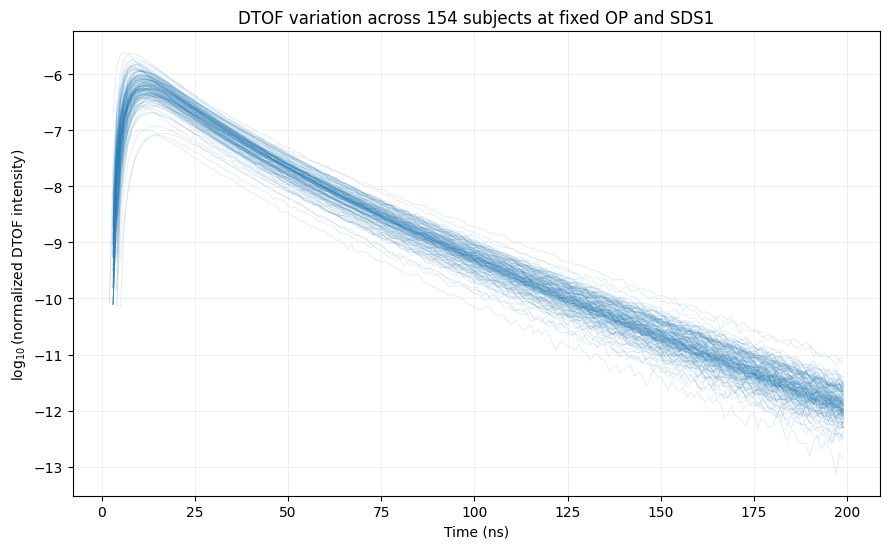

In [28]:
time_ns = np.arange(dtof_curves.shape[1], dtype=np.float64) * TIME_BIN_WIDTH_NS
median_log_curve = np.full(dtof_curves.shape[1], np.nan, dtype=np.float64)
valid_time_bins = np.any(positive_mask, axis=0)
median_log_curve[valid_time_bins] = np.nanmedian(
    log_dtof_curves[:, valid_time_bins], axis=0
)

fig, ax = plt.subplots(figsize=(9.0, 5.6))
for subject_curve in log_dtof_curves:
    ax.plot(time_ns, subject_curve, color='#2C7FB8', linewidth=0.65, alpha=0.14)

# ax.plot(
#     time_ns,
#     median_log_curve,
#     color='#111111',
#     linewidth=2.0,
#     label='Across-subject median',
# )
ax.set_title(f'DTOF variation across {NUM_SUBJECTS} subjects at fixed OP and {SDS_LABEL}')
ax.set_xlabel('Time (ns)')
ax.set_ylabel(
    r'$\log_{10}$(normalized DTOF intensity)'
)
ax.grid(alpha=0.2, linewidth=0.6)
ax.legend(frameon=False, loc='best')

op_text = np.array2string(reference_op, precision=3, separator=', ')
# ax.text(
#     0.99,
#     0.02,
#     (
#         f'OP index = {OP_INDEX}\n'
#         f'OP vector = {op_text}\n'
#         f'{SDS_LABEL} = {SDS_DISTANCE_CM:g} cm, {WAVELENGTH_NM} nm'
#     ),
#     transform=ax.transAxes,
#     ha='right',
#     va='bottom',
#     fontsize=8.5,
#     bbox={'facecolor': 'white', 'edgecolor': '0.75', 'alpha': 0.9, 'pad': 4},
# )
fig.tight_layout()

if SAVE_FIGURE:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_PATH, dpi=300, bbox_inches='tight')
    print(f'Saved figure: {FIGURE_PATH.relative_to(ROOT)}')

plt.show()

## Interpretation boundary

With OP condition, SDS, and wavelength held fixed, the remaining curve differences are consistent with subject-dependent photon propagation caused by differences in head geometry and tissue configuration, together with simulation variability. This visualization motivates examining individual information in DTOF, but by itself does not isolate a single anatomical mechanism.